# Lab 2 — What Did the Campaign Deliver?
Name: Anna Zaporozhets | Group: КМ-42

## Setup

In [2]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt

DATA = kagglehub.dataset_download(
    "shkarupylomaxim/adtech-lab1-tv-panel/versions/3"
)

programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
commercials = pd.read_parquet(f"{DATA}/commercials.parquet")
rate_card = pd.read_parquet(f"{DATA}/rate_card.parquet")


Using Colab cache for faster access to the 'adtech-lab1-tv-panel' dataset.


## Task 1.1 — Size

In [3]:
brand_a = commercials.loc[commercials["brand"] == "BRAND_A"].copy()

print("Spots:", commercials["ad_airing_id"].nunique())
print("Pods:", commercials["pod_id"].nunique())
print("Brands:", commercials["brand"].nunique())
print("Categories:", commercials["category"].nunique())
print("BRAND_A spots:", len(brand_a))

brand_a_by_network = (
    brand_a.groupby("network_code")
    .size()
    .reset_index(name="spots")
    .sort_values("spots", ascending=False)
    .reset_index(drop=True)
)

display(brand_a_by_network)

Spots: 167720
Pods: 22359
Brands: 95
Categories: 14
BRAND_A spots: 300


,network_code,spots
0,FNC,40
1,HGTV,39
2,FX,38
3,HIST,37
4,FOOD,33
5,BRAVO,33
6,ABC,29
7,CBS,22
8,NBC,16
9,FOX,13


## Task 1.2 — Ad load

In [4]:
commercials["start_ts"] = pd.to_datetime(commercials["start_ts"])

hourly_ads = (
    commercials.assign(clock_hour=commercials["start_ts"].dt.floor("h"))
    .groupby(["network_code", "clock_hour"])["length_sec"]
    .sum()
    .div(60)
    .reset_index(name="ad_minutes")
)

ad_load = (
    hourly_ads.groupby("network_code")["ad_minutes"]
    .mean()
    .reset_index(name="ad_minutes_per_hour")
    .sort_values("ad_minutes_per_hour", ascending=False)
    .reset_index(drop=True)
)

display(ad_load.round(1))
print("Heaviest ad load:", ad_load.iloc[0]["network_code"])

,network_code,ad_minutes_per_hour
0,FNC,15.6
1,BRAVO,13.4
2,HGTV,13.3
3,HIST,13.2
4,FOOD,13.1
5,FX,12.9
6,CBS,12.1
7,ABC,11.8
8,NBC,11.8
9,FOX,11.8


Heaviest ad load: FNC


**Answer:** Broadcast networks have whole hours without national ads because some hours are allocated to local stations, where advertising is sold locally and is not included in this national ad log. The dataset also excludes commercials during paid programming and the vice-presidential debate. The average ad load is calculated only over hours that carried ads.

## Task 1.3 — Price everything

In [16]:
# Add program names to all spots.
priced_ads = commercials.merge(
    programs[["telecast_id", "program_name"]],
    on="telecast_id",
    how="left",
    validate="many_to_one"
)

# Identify program-specific rates.
is_program = (
    rate_card["program_name"].fillna("").str.strip().ne("")
)

program_rates = rate_card.loc[
    is_program,
    ["network_code", "program_name", "daypart", "cost_30s_usd"]
].rename(columns={"daypart": "selling_daypart"})

# Program-specific rates take priority.
priced_ads = priced_ads.merge(
    program_rates,
    on=["network_code", "program_name"],
    how="left",
    validate="many_to_one"
)

priced_ads["from_program_row"] = priced_ads["cost_30s_usd"].notna()

# The broadcast day starts at 06:00.
shifted = pd.to_datetime(priced_ads["start_ts"]) - pd.Timedelta(hours=6)
priced_ads["broadcast_weekday"] = shifted.dt.dayofweek
priced_ads["broadcast_minute"] = (
    shifted.dt.hour * 60
    + shifted.dt.minute
    + shifted.dt.second / 60
)

def broadcast_minutes(value):
    hours, minutes = map(int, value.split(":"))
    return hours * 60 + minutes - 360

time_matches = pd.Series(0, index=priced_ads.index)

# Apply time-based rates only to spots without a program-specific rate.
for row in rate_card.loc[~is_program].itertuples(index=False):
    mask = (
        ~priced_ads["from_program_row"]
        & priced_ads["network_code"].eq(row.network_code)
        & priced_ads["broadcast_weekday"].isin(row.weekdays)
        & priced_ads["broadcast_minute"].ge(
            broadcast_minutes(row.start_time)
        )
        & priced_ads["broadcast_minute"].lt(
            broadcast_minutes(row.end_time)
        )
    )

    time_matches.loc[mask] += 1
    priced_ads.loc[mask, "selling_daypart"] = row.daypart
    priced_ads.loc[mask, "cost_30s_usd"] = row.cost_30s_usd

# Adjust the price for spot length.
priced_ads["cost_usd"] = (
    priced_ads["cost_30s_usd"] * priced_ads["length_sec"] / 30
)

print("Spots without a price:", priced_ads["cost_usd"].isna().sum())

assert priced_ads["cost_usd"].notna().all(), "Some spots have no price."
assert time_matches.loc[
    ~priced_ads["from_program_row"]
].eq(1).all(), "Time-based rates must match exactly once."

# Calculate total value and the share from program-specific rates.
priced_ads["program_value_usd"] = priced_ads["cost_usd"].where(
    priced_ads["from_program_row"], 0
)

network_value = (
    priced_ads.groupby("network_code")
    .agg(
        total_value_usd=("cost_usd", "sum"),
        program_value_usd=("program_value_usd", "sum")
    )
)

network_value["rate_card_value_usd_m"] = (
    network_value["total_value_usd"] / 1_000_000
)
network_value["program_share"] = (
    network_value["program_value_usd"] / network_value["total_value_usd"]
)

display(
    network_value[
        ["rate_card_value_usd_m", "program_share"]
    ]
    .sort_values("rate_card_value_usd_m", ascending=False)
    .style.format({
        "rate_card_value_usd_m": "{:.6f}",
        "program_share": "{:.3f}"
    })
)

# Keep the priced campaign for the next tasks.
brand_a = priced_ads.loc[priced_ads["brand"] == "BRAND_A"].copy()

Spots without a price: 0


,rate_card_value_usd_m,program_share
network_code,,
CBS,818.778150,0.230
NBC,724.324400,0.342
ABC,708.787400,0.432
FOX,696.172750,0.835
FNC,315.845400,0.000
HGTV,58.102925,0.000
FX,42.505610,0.000
FOOD,42.148705,0.000
HIST,40.085320,0.000


## Task 2.1 — Delivery

In [7]:
# Select persons and attach their ages.
ages = (
    viewer_attributes.loc[
        viewer_attributes["attr_id"].eq(300),
        ["respondent_id", "value"]
    ]
    .rename(columns={"value": "age"})
    .copy()
)
ages["age"] = pd.to_numeric(ages["age"], errors="raise")

person_weights = daily_weights.loc[
    daily_weights["resp_type"].isin(["R", "L"])
].copy()

person_weights["broadcast_date"] = pd.to_datetime(
    person_weights["broadcast_date"]
).dt.normalize()

person_weights = person_weights.merge(
    ages,
    on="respondent_id",
    how="left",
    validate="many_to_one"
)

assert person_weights["age"].notna().all(), "Missing ages."

person_weights = person_weights.loc[
    person_weights["age"].ge(2)
].copy()

# Prepare campaign spots.
campaign = brand_a.copy()
campaign["start_ts"] = pd.to_datetime(campaign["start_ts"])
campaign["broadcast_date"] = (
    campaign["start_ts"] - pd.Timedelta(hours=6)
).dt.normalize()

# Prepare viewing sessions for persons only.
sessions = viewings.loc[
    viewings["resp_type"].isin(["R", "L"]),
    ["respondent_id", "network_code", "start_ts", "end_ts"]
].copy()

sessions["start_ts"] = pd.to_datetime(sessions["start_ts"])
sessions["end_ts"] = pd.to_datetime(sessions["end_ts"])

sessions_by_network = {
    network: group
    for network, group in sessions.groupby("network_code")
}

# Build one exposure row per spot and person.
exposure_parts = []

for spot in campaign.itertuples(index=False):
    network_sessions = sessions_by_network.get(spot.network_code)

    if network_sessions is None:
        continue

    viewers = network_sessions.loc[
        network_sessions["start_ts"].le(spot.start_ts)
        & network_sessions["end_ts"].gt(spot.start_ts),
        ["respondent_id"]
    ].drop_duplicates()

    exposure_parts.append(
        viewers.assign(
            ad_airing_id=spot.ad_airing_id,
            network_code=spot.network_code,
            broadcast_date=spot.broadcast_date
        )
    )

exposures = pd.concat(exposure_parts, ignore_index=True)

# Use the weight belonging to the spot's broadcast day.
exposures = exposures.merge(
    person_weights[
        ["respondent_id", "broadcast_date", "weight", "age"]
    ],
    on=["respondent_id", "broadcast_date"],
    how="left",
    validate="many_to_one"
)

assert exposures["weight"].notna().all(), "Missing exposure weights."
assert exposures["age"].notna().all(), "Missing exposure ages."

# Monthly weights include all in-tab days, including non-viewing days.
monthly_weights = person_weights.groupby("respondent_id")["weight"].mean()

person_ages = person_weights.groupby("respondent_id")["age"].first()

def calculate_delivery(min_age, max_age):
    audience_ids = person_ages.index[
        person_ages.between(min_age, max_age)
    ]

    audience_weights = person_weights.loc[
        person_weights["respondent_id"].isin(audience_ids)
    ]

    audience_exposures = exposures.loc[
        exposures["respondent_id"].isin(audience_ids)
    ]

    # Daily audience universe includes viewers and non-viewers.
    daily_universe = audience_weights.groupby(
        "broadcast_date"
    )["weight"].sum()

    impressions_by_spot = audience_exposures.groupby(
        "ad_airing_id"
    )["weight"].sum()

    spot_metrics = campaign[
        ["ad_airing_id", "network_code", "broadcast_date"]
    ].copy()

    spot_metrics["impressions"] = (
        spot_metrics["ad_airing_id"]
        .map(impressions_by_spot)
        .fillna(0)
    )

    spot_metrics["universe"] = (
        spot_metrics["broadcast_date"].map(daily_universe)
    )

    assert spot_metrics["universe"].gt(0).all(), "Invalid universe."

    spot_metrics["rating"] = (
        spot_metrics["impressions"] / spot_metrics["universe"] * 100
    )

    impressions = spot_metrics["impressions"].sum()
    grps = spot_metrics["rating"].sum()

    reached_ids = audience_exposures["respondent_id"].unique()

    reach = (
        monthly_weights.reindex(reached_ids).sum()
        / monthly_weights.reindex(audience_ids).sum()
        * 100
    )

    frequency = grps / reach if reach > 0 else float("nan")

    return {
        "impressions": impressions,
        "grps": grps,
        "reach": reach,
        "frequency": frequency,
        "spot_metrics": spot_metrics
    }

p2 = calculate_delivery(2, float("inf"))
a18_49 = calculate_delivery(18, 49)

print("P2+ impressions (M):", f"{p2['impressions'] / 1_000_000:.1f}")
print("P2+ GRPs:", f"{p2['grps']:.1f}")
print("P2+ reach (%):", f"{p2['reach']:.1f}")
print("P2+ average frequency:", f"{p2['frequency']:.2f}")
print("A18-49 impressions (M):", f"{a18_49['impressions'] / 1_000_000:.1f}")
print("A18-49 GRPs:", f"{a18_49['grps']:.1f}")
print("A18-49 reach (%):", f"{a18_49['reach']:.1f}")
print("A18-49 average frequency:", f"{a18_49['frequency']:.2f}")

P2+ impressions (M): 418.8
P2+ GRPs: 132.0
P2+ reach (%): 43.5
P2+ average frequency: 3.03
A18-49 impressions (M): 81.1
A18-49 GRPs: 60.4
A18-49 reach (%): 30.5
A18-49 average frequency: 1.98


## Task 2.2 — Frequency distribution

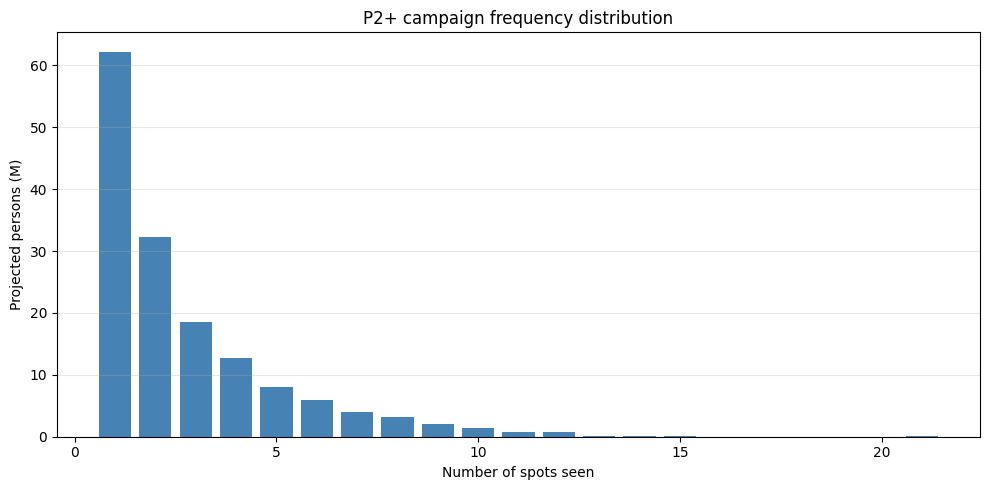

Share of impressions at 5+ exposures: 0.444


In [8]:
# Count unique spots seen by each reached person.
person_frequency = (
    exposures.groupby("respondent_id")["ad_airing_id"]
    .nunique()
    .rename("spots_seen")
    .to_frame()
)

# Project panelists to persons using monthly average weights.
person_frequency["monthly_weight"] = monthly_weights.reindex(
    person_frequency.index
)

frequency_distribution = (
    person_frequency.groupby("spots_seen")["monthly_weight"]
    .sum()
)

# Include missing frequency values as zero.
frequency_distribution = frequency_distribution.reindex(
    range(1, int(person_frequency["spots_seen"].max()) + 1),
    fill_value=0
)

plt.figure(figsize=(10, 5))
plt.bar(
    frequency_distribution.index,
    frequency_distribution.values / 1_000_000,
    color="steelblue"
)
plt.xlabel("Number of spots seen")
plt.ylabel("Projected persons (M)")
plt.title("P2+ campaign frequency distribution")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Calculate the share of impressions delivered to people with 5+ exposures.
# Use broadcast-day weights, as in Task 2.1.
high_frequency_ids = person_frequency.index[
    person_frequency["spots_seen"].ge(5)
]

impressions_5plus = exposures.loc[
    exposures["respondent_id"].isin(high_frequency_ids),
    "weight"
].sum()

share_5plus = impressions_5plus / exposures["weight"].sum()

print("Share of impressions at 5+ exposures:", f"{share_5plus:.3f}")

**Answer:** The average P2+ frequency was 3.03, but the distribution was right-skewed: most reached people saw only one or two spots, while a smaller group saw many more. People with five or more exposures received 44.4% of all impressions. Therefore, the average is useful as an overall measure but does not adequately describe the uneven distribution of exposures.

## Task 2.3 — On target?

In [9]:
# Calculate the target's share of all campaign impressions.
target_share = a18_49["impressions"] / p2["impressions"]

print("Share of impressions on A18-49:", f"{target_share:.3f}")

# Compare target delivery across networks.
network_target = (
    p2["spot_metrics"]
    .groupby("network_code")["impressions"]
    .sum()
    .rename("p2_impressions")
    .to_frame()
)

network_target["target_impressions"] = (
    a18_49["spot_metrics"]
    .groupby("network_code")["impressions"]
    .sum()
)

network_target["target_share"] = (
    network_target["target_impressions"]
    / network_target["p2_impressions"]
)

network_target["campaign_impression_share"] = (
    network_target["p2_impressions"] / p2["impressions"]
)

# Each network's contribution to the campaign's gap from 42%.
network_target["gap_contribution_pp"] = (
    (
        network_target["target_impressions"]
        - 0.42 * network_target["p2_impressions"]
    )
    / p2["impressions"]
    * 100
)

display(
    network_target[
        ["target_share", "campaign_impression_share", "gap_contribution_pp"]
    ]
    .sort_values("gap_contribution_pp")
    .style.format({
        "target_share": "{:.3f}",
        "campaign_impression_share": "{:.3f}",
        "gap_contribution_pp": "{:.1f}"
    })
)

Share of impressions on A18-49: 0.194


,target_share,campaign_impression_share,gap_contribution_pp
network_code,,,
CBS,0.154,0.212,-5.7
ABC,0.180,0.225,-5.4
FNC,0.047,0.138,-5.1
FOX,0.242,0.182,-3.2
NBC,0.189,0.099,-2.3
HGTV,0.306,0.059,-0.7
HIST,0.202,0.029,-0.6
FOOD,0.316,0.023,-0.2
BRAVO,0.554,0.012,0.2


**Answer:** A18-49 received 19.4% of campaign impressions, compared with approximately 42% of all persons. The campaign therefore under-delivered against the target in impression composition by 22.6 percentage points. CBS, ABC and FNC made the largest negative contributions: their target shares were only 15.4%, 18.0% and 4.7%, respectively. FX and BRAVO had target shares of 65.1% and 55.4%, but together supplied only about 3.2% of all campaign impressions, so they could not offset the shortfall.

## Task 3.1 — Cost

In [10]:
# Total rate-card cost of the BRAND_A campaign.
assert campaign["cost_usd"].notna().all(), "Missing spot costs."
campaign_cost = campaign["cost_usd"].sum()

# CPM: cost per 1,000 impressions.
p2_cpm = campaign_cost / p2["impressions"] * 1000
a18_49_cpm = campaign_cost / a18_49["impressions"] * 1000

# CPP: cost per gross rating point.
p2_cpp = campaign_cost / p2["grps"]
a18_49_cpp = campaign_cost / a18_49["grps"]

print("Campaign cost (USD):", f"{campaign_cost:.0f}")
print("P2+ CPM (USD):", f"{p2_cpm:.2f}")
print("P2+ CPP (USD):", f"{p2_cpp:.0f}")
print("A18-49 CPM (USD):", f"{a18_49_cpm:.2f}")
print("A18-49 CPP (USD):", f"{a18_49_cpp:.0f}")

Campaign cost (USD): 7420270
P2+ CPM (USD): 17.72
P2+ CPP (USD): 56221
A18-49 CPM (USD): 91.53
A18-49 CPP (USD): 122836


## Task 3.2 — By network

In [11]:
# Count campaign spots and sum their costs by network.
network_costs = (
    campaign.groupby("network_code")
    .agg(
        spots=("ad_airing_id", "nunique"),
        cost_usd=("cost_usd", "sum")
    )
)

# Add impressions for both audiences.
network_costs["p2_impressions"] = (
    p2["spot_metrics"]
    .groupby("network_code")["impressions"]
    .sum()
)

network_costs["a18_49_impressions"] = (
    a18_49["spot_metrics"]
    .groupby("network_code")["impressions"]
    .sum()
)

# Avoid division by zero if a network has no measured impressions.
network_costs["p2_cpm_usd"] = (
    network_costs["cost_usd"]
    / network_costs["p2_impressions"].replace(0, float("nan"))
    * 1000
)

network_costs["a18_49_cpm_usd"] = (
    network_costs["cost_usd"]
    / network_costs["a18_49_impressions"].replace(0, float("nan"))
    * 1000
)

network_costs["budget_share"] = (
    network_costs["cost_usd"] / campaign_cost
)

# Display impressions in millions.
network_costs["p2_impressions_m"] = (
    network_costs["p2_impressions"] / 1_000_000
)
network_costs["a18_49_impressions_m"] = (
    network_costs["a18_49_impressions"] / 1_000_000
)

display(
    network_costs[
        [
            "spots",
            "cost_usd",
            "budget_share",
            "p2_impressions_m",
            "a18_49_impressions_m",
            "p2_cpm_usd",
            "a18_49_cpm_usd"
        ]
    ]
    .sort_values("cost_usd", ascending=False)
    .style.format({
        "spots": "{:.0f}",
        "cost_usd": "{:.0f}",
        "budget_share": "{:.3f}",
        "p2_impressions_m": "{:.1f}",
        "a18_49_impressions_m": "{:.1f}",
        "p2_cpm_usd": "{:.2f}",
        "a18_49_cpm_usd": "{:.2f}"
    }, na_rep="N/A")
)

,spots,cost_usd,budget_share,p2_impressions_m,a18_49_impressions_m,p2_cpm_usd,a18_49_cpm_usd
network_code,,,,,,,
FOX,13,2434700,0.328,76.3,18.4,31.93,132.03
ABC,29,1625700,0.219,94.2,17.0,17.26,95.69
CBS,22,1488700,0.201,89.0,13.7,16.73,108.72
NBC,16,796800,0.107,41.4,7.8,19.23,101.72
FNC,40,526300,0.071,57.8,2.7,9.11,193.70
HGTV,39,230000,0.031,24.7,7.6,9.33,30.45
FOOD,33,96620,0.013,9.5,3.0,10.19,32.29
FX,38,92200,0.012,8.5,5.6,10.82,16.61
HIST,37,79640,0.011,12.3,2.5,6.46,32.05


**Answer:** Most of the budget went to FOX (2434700 USD; 32.8%), ABC (1625700 USD; 21.9%) and CBS (1488700 USD; 20.1%), together accounting for about 74.8% of total spending. FX and BRAVO delivered the cheapest A18-49 impressions, with target CPMs of 16.61 USD and 17.61 USD, respectively. However, each received only a small share of the budget. FNC had the highest target CPM (193.70 USD), despite a relatively low P2+ CPM (9.11 USD), because few of its impressions reached the target audience.

## Task 3.3 — Guarantee

In [12]:
# Check the guarantee using unrounded P2+ GRPs.
guaranteed_grps = 150.0

guarantee_met = bool(p2["grps"] >= guaranteed_grps)
make_good_grps = max(0.0, guaranteed_grps - p2["grps"])

# Estimate the value at the campaign's P2+ CPP.
make_good_value = make_good_grps * p2_cpp

print("Guarantee met:", guarantee_met)
print("Make-good GRPs owed:", f"{make_good_grps:.1f}")
print("Value of make-goods (USD):", f"{make_good_value:.0f}")

Guarantee met: False
Make-good GRPs owed: 18.0
Value of make-goods (USD): 1012869


## Task 4 — Do networks add up?

In [13]:
big_networks = ["CBS", "NBC", "ABC", "FOX", "FNC"]
small_networks = ["FX", "BRAVO", "HGTV", "FOOD", "HIST"]

# Identify unique persons reached by each network group.
big_ids = set(
    exposures.loc[
        exposures["network_code"].isin(big_networks),
        "respondent_id"
    ]
)

small_ids = set(
    exposures.loc[
        exposures["network_code"].isin(small_networks),
        "respondent_id"
    ]
)

whole_ids = big_ids | small_ids
overlap_ids = big_ids & small_ids
added_ids = small_ids - big_ids

# Use the same P2+ universe and monthly weights as in Task 2.1.
p2_universe = monthly_weights.sum()

def weighted_reach(person_ids):
    return (
        monthly_weights.reindex(list(person_ids)).sum()
        / p2_universe
        * 100
    )

reach_big = weighted_reach(big_ids)
reach_small = weighted_reach(small_ids)
reach_whole = weighted_reach(whole_ids)
overlap = weighted_reach(overlap_ids)

# Under independence: P(big and small) = P(big) * P(small).
overlap_independent = reach_big * reach_small / 100

# Incremental reach includes only people not reached by big networks.
reach_added_small = weighted_reach(added_ids)

cost_big = campaign.loc[
    campaign["network_code"].isin(big_networks),
    "cost_usd"
].sum()

cost_small = campaign.loc[
    campaign["network_code"].isin(small_networks),
    "cost_usd"
].sum()

cost_per_added_point_small = (
    cost_small / reach_added_small
    if reach_added_small > 0
    else float("inf")
)

cost_per_point_big = (
    cost_big / reach_big
    if reach_big > 0
    else float("inf")
)

# Check the inclusion-exclusion identity.
assert abs(
    reach_whole - (reach_big + reach_small - overlap)
) < 1e-8, "Reach totals are inconsistent."

assert abs(
    reach_whole - p2["reach"]
) < 1e-8, "Campaign reach differs from Task 2.1."

print("Reach, big networks (%):", f"{reach_big:.1f}")
print("Reach, small networks (%):", f"{reach_small:.1f}")
print("Reach, whole campaign (%):", f"{reach_whole:.1f}")
print("Overlap (%):", f"{overlap:.1f}")
print("Overlap if independent (%):", f"{overlap_independent:.1f}")
print("Reach added by small networks (points):", f"{reach_added_small:.1f}")
print("Cost per added reach point, small (USD):", f"{cost_per_added_point_small:.0f}")
print("Cost per reach point, big (USD):", f"{cost_per_point_big:.0f}")

Reach, big networks (%): 39.8
Reach, small networks (%): 12.4
Reach, whole campaign (%): 43.5
Overlap (%): 8.7
Overlap if independent (%): 4.9
Reach added by small networks (points): 3.7
Cost per added reach point, small (USD): 148706
Cost per reach point, big (USD): 172456


**Answer:** Reach does not add across network groups because some people saw spots on both. Big networks reached 39.8% of P2+, small networks reached 12.4%, and the whole campaign reached 43.5%, with an overlap of 8.7%. This exceeds the 4.9% overlap expected under independence. Approximately 70% of people reached by small networks were also reached by big networks, compared with 39.8% of P2+ overall. This may reflect heavier TV viewing and viewing across multiple networks.

Small networks added 3.7 percentage points of reach. Each added point cost 148706 USD, compared with 172456 USD per reach point on big networks. On this P2+ reach-cost measure, the small-network spending was worthwhile: it extended coverage at a lower cost per additional point, despite substantial audience overlap.

## Task 5 — How sure are we?

In [15]:
# Start with all campaign spots, including those with zero viewers.
spot_uncertainty = p2["spot_metrics"].copy()

panelists_per_spot = (
    exposures.groupby("ad_airing_id")["respondent_id"].nunique()
)

spot_uncertainty["panelists"] = (
    spot_uncertainty["ad_airing_id"]
    .map(panelists_per_spot)
    .fillna(0)
    .astype(int)
)

# Count all P2+ persons in-tab on each broadcast day.
daily_panel_size = (
    person_weights.groupby("broadcast_date")["respondent_id"]
    .nunique()
)

spot_uncertainty["n"] = (
    spot_uncertainty["broadcast_date"].map(daily_panel_size)
)

assert spot_uncertainty["n"].gt(0).all(), "Invalid panel size."

# Standard error in rating points.
p = spot_uncertainty["rating"] / 100

spot_uncertainty["se"] = (
    p * (1 - p) / spot_uncertainty["n"]
) ** 0.5 * 100

# Relative SE is undefined for a zero rating.
# Exclude these cases from medians and report zero cells separately.
spot_uncertainty["relative_se"] = (
    spot_uncertainty["se"]
    / spot_uncertainty["rating"].replace(0, float("nan"))
)

uncertainty_by_network = (
    spot_uncertainty.groupby("network_code")
    .agg(
        median_panelists_per_spot=("panelists", "median"),
        median_relative_se=("relative_se", "median")
    )
)

display(
    uncertainty_by_network.style.format({
        "median_panelists_per_spot": "{:.1f}",
        "median_relative_se": "{:.3f}"
    }, na_rep="N/A")
)

spots_without_panelists = int(
    spot_uncertainty["panelists"].eq(0).sum()
)

median_relative_se_big = spot_uncertainty.loc[
    spot_uncertainty["network_code"].isin(big_networks),
    "relative_se"
].median()

median_relative_se_small = spot_uncertainty.loc[
    spot_uncertainty["network_code"].isin(small_networks),
    "relative_se"
].median()

# Attribute 202 marks female respondents.
female_ids = viewer_attributes.loc[
    viewer_attributes["attr_id"].eq(202),
    "respondent_id"
].unique()

w18_34_exposures = exposures.loc[
    exposures["respondent_id"].isin(female_ids)
    & exposures["age"].between(18, 34)
]

w18_34_counts = (
    w18_34_exposures.groupby("ad_airing_id")["respondent_id"]
    .nunique()
)

spot_uncertainty["w18_34_panelists"] = (
    spot_uncertainty["ad_airing_id"]
    .map(w18_34_counts)
    .fillna(0)
    .astype(int)
)

w18_34_zero_cells = int(
    spot_uncertainty["w18_34_panelists"].eq(0).sum()
)

print("Spots seen by no panelist:", spots_without_panelists)
print("Median relative SE, big networks:", f"{median_relative_se_big:.3f}")
print("Median relative SE, small networks:", f"{median_relative_se_small:.3f}")
print("W18-34 zero-cell spots:", w18_34_zero_cells)

,median_panelists_per_spot,median_relative_se
network_code,,
ABC,57.0,0.123
BRAVO,3.0,0.540
CBS,69.0,0.113
FNC,31.0,0.164
FOOD,5.0,0.423
FOX,145.0,0.080
FX,5.5,0.423
HGTV,11.0,0.301
HIST,5.0,0.460


Spots seen by no panelist: 10
Median relative SE, big networks: 0.122
Median relative SE, small networks: 0.417
W18-34 zero-cell spots: 171


**Answer:** Ten spots were seen by no panelist and therefore received a zero P2+ rating. This means no viewing was observed in the panel, not that nobody in the population saw the spots. Small networks rely on fewer observations: the median was 3 panelists per spot for BRAVO, compared with 145 for FOX. The median relative SE was 0.122 for big networks and 0.417 for small networks, indicating substantially greater uncertainty for small networks. Zero ratings were excluded from relative-SE medians because relative SE is undefined when the rating is zero.

For W18-34, 171 of the 300 spots (57.0%) had no observed viewers. Individual spot ratings for this audience are therefore too sparse for confident comparisons. The client should receive panelist counts and clear zero-cell flags alongside the estimates. Aggregating spots by network or daypart, or examining campaign-level delivery, would provide a more useful summary, although uncertainty would remain. The SE formula assumes a simple random sample and provides a lower bound; weighting and panel design can make actual errors larger.